# Business Idea Evaluator

A LangGraph workflow that evaluates a startup idea in three phases:

1. **Clarify** – `decide_node` asks the founder one follow-up question at a time until the LLM replies `DONE`.
2. **Fan out** – four advisor nodes (market, legal, technical, strategy) run in parallel, each writing its own report.
3. **Synthesize** – `collect_and_report` merges the four reports into one final evaluation.

```
decide_node ──(needs info)──> ask_user_node ──┐
     ^                                        │
     └────────────────────────────────────────┘
     │
     └──(DONE)──> fanout ──> 4 advisors (parallel) ──> collect_and_report ──> END
```

Requires `OPENAI_API_KEY` in a `.env` file at the project root.

## Required Packages

In [17]:
import os, operator
from typing import List, Annotated, Dict
from typing_extensions import TypedDict

from openai import OpenAI
from langchain_openai import ChatOpenAI
from langchain_core.messages import SystemMessage, HumanMessage, AIMessage, BaseMessage
from langgraph.graph.message import add_messages
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver
from pydantic import BaseModel, Field
from IPython.display import display, Markdown, Image
from dotenv import load_dotenv

In [18]:
# Load OPENAI_API_KEY (and any other secrets) from the project's .env file
# into the process environment, where ChatOpenAI picks it up automatically.
load_dotenv()

True

In [19]:
# Shared chat model used by every node in the graph.
# temperature=0 keeps the clarifying questions and reports as deterministic as possible.
llm = ChatOpenAI(model_name="gpt-4o-mini", temperature=0)

In [20]:
class State(TypedDict):
    """Shared state passed between every node in the evaluation graph.

    Fields annotated with a reducer are *merged* when a node returns them,
    rather than overwritten. This matters for the parallel advisor nodes,
    which all write to ``advisor_reports`` in the same step.

    Attributes:
        idea: The founder's original one-line description of the idea.
        messages: Clarifying conversation between the founder and the LLM.
            ``add_messages`` appends new messages (and de-duplicates by ID).
        advisor_reports: Advisor name -> report text. ``operator.or_`` merges
            each advisor's single-entry dict into the combined dict.
        final_report: The synthesized evaluation produced at the end.
    """

    idea: str
    messages: Annotated[List[BaseMessage], add_messages]
    advisor_reports: Annotated[Dict[str, str], operator.or_]
    final_report: str

In [21]:
# System prompt for the clarification loop. The exact word "DONE" is the
# contract `route` relies on to decide when to stop asking questions.
base_system_message = SystemMessage(
    content="""You are a helpful tool
    Your job: decide whether you have enough information about a business start up idea.
    If not, ask ONE precise follow-up question.
    If yes, say: DONE
    """
)

In [22]:
def decide_node(state: State):
    """Ask the LLM whether the idea is clear enough to evaluate.

    The LLM sees the system prompt plus the full conversation so far and
    replies with either one follow-up question or the word ``DONE``.

    Returns:
        A state update appending the LLM's reply to ``messages``.
    """
    conversation = [base_system_message] + state['messages']
    ai_reply: AIMessage = llm.invoke(conversation)
    return {"messages": [ai_reply]}

In [23]:
def route(state: State):
    """Choose the next node after ``decide_node``.

    Returns:
        ``"fanout"`` if the LLM's last reply is exactly ``DONE`` (case- and
        whitespace-insensitive), otherwise ``"ask_user_node"`` so the founder
        can answer the follow-up question.
    """
    last_ai_message: AIMessage = state['messages'][-1]
    if isinstance(last_ai_message, AIMessage) and last_ai_message.content.strip().upper() == "DONE":
        return "fanout"
    return "ask_user_node"

In [24]:
def ask_user_node(state: State):
    """Show the LLM's follow-up question and collect the founder's answer.

    Blocks on ``input()``, so the graph must be run interactively.

    Returns:
        A state update adding the founder's answer to ``messages``.
    """
    question: str = state['messages'][-1].content
    print(f"Assistant asked: {question}")
    human_input = input("You: ")
    # add_messages de-duplicates by message ID, so re-sending the existing
    # history alongside the new answer only appends the new HumanMessage.
    new_messages = state['messages'] + [HumanMessage(content=human_input)]
    # Note: "human_advisor_feedback" is not a State field, so LangGraph drops it.
    return {"messages": new_messages, "human_advisor_feedback": human_input}

In [25]:
# Advisor nodes
# Each advisor runs in parallel after `fanout`, reviews the full clarifying
# conversation from its own angle, and returns a single-entry dict that the
# `operator.or_` reducer merges into `advisor_reports`.

## Market Analyst Advisor
def market_analyst_advisor(state: State):
    """Assess market size, competition, target customers, and timing.

    Returns:
        ``{"advisor_reports": {"market_analyst": <report>}}``.
    """
    prompt = f"""
    You are a helpful senior MARKET ANALYST that gets an idea as an input. You need to evaluate the market potential
    , competition, target demographics, and any other relevant market factors for the business idea.
    Conduct marker sizing and competitor research, indentify target customers and segments assess timing, trends, and macroeconomic influences.
    Idea:
    {state["messages"]}
    """
    report = llm.invoke([SystemMessage(content=prompt)])
    return {"advisor_reports": {"market_analyst": report.content}}

## Legal Advisor
def legal_advisor(state: State):
    """Assess legal risk, regulatory compliance, and intellectual property.

    Returns:
        ``{"advisor_reports": {"legal_advisor": <report>}}``.
    """
    prompt = f"""
    You are a helpful senior LEGAL ADVISOR that gets an idea as an input. You need to evaluate the legal and regulatory aspects of the business idea.
    Assess potential legal risks, compliance requirements, intellectual property considerations, and any other relevant legal factors for the business idea.
    Idea:
    {state["messages"]}
    """
    report = llm.invoke([SystemMessage(content=prompt)])
    return {"advisor_reports": {"legal_advisor": report.content}}

## Technical Advisor
def technical_advisor(state: State):
    """Assess technical feasibility, scalability, and infrastructure needs.

    Returns:
        ``{"advisor_reports": {"technical_advisor": <report>}}``.
    """
    prompt = f"""
    You are a helpful senior TECHNICAL ADVISOR that gets an idea as an input. You need to evaluate the technical feasibility and implementation aspects of the business idea.
    Assess potential technical challenges, scalability, infrastructure requirements, and any other relevant technical factors for the business idea.
    Idea:
    {state["messages"]}
    """
    report = llm.invoke([SystemMessage(content=prompt)])
    return {"advisor_reports": {"technical_advisor": report.content}}

## Strategist Advisor
def strategist_advisor(state: State):
    """Assess positioning, competitive advantage, growth, and partnerships.

    Returns:
        ``{"advisor_reports": {"strategist_advisor": <report>}}``.
    """
    prompt = f"""
    You are a helpful senior STRATEGIST that gets an idea as an input. You need to evaluate the overall business strategy and market positioning of the business idea.
    Assess potential growth opportunities, competitive advantages, strategic partnerships, and any other relevant strategic factors for the business idea.
    Idea:
    {state["messages"]}
    """
    report = llm.invoke([SystemMessage(content=prompt)])
    return {"advisor_reports": {"strategist_advisor": report.content}}


In [26]:
def collect_and_report(state: State):
    """Merge the four advisor reports into one final evaluation.

    Displays the result as Markdown in the notebook.

    Returns:
        ``{"final_report": <report>}``, or an empty update if any advisor
        report is still missing.
    """
    # Guard against running before every advisor has reported; the fan-in
    # edges normally guarantee all four are present by the time we get here.
    if len(state['advisor_reports']) < 4:
        return {}
    report_prompts = f"""
    You are a senior consultant. Combine the four advisor notes below into a clear,
    structured evaluation report for the founder.
    Advisor Reports:
    {state['advisor_reports']}
    """
    report = llm.invoke([SystemMessage(content=report_prompts)]).content
    display(Markdown(f"### Final Evaluation Report\n{report}"))
    return {"final_report": report}

In [27]:
# Build the graph over the shared State schema; nodes and edges are added below.
graph_builder = StateGraph(State)

In [28]:
# Register every node. Names here are the identifiers used by the edges below.
graph_builder.add_node("decide_node", decide_node)
graph_builder.add_node("ask_user_node", ask_user_node)
# No-op hub: lets one conditional branch ("fanout") start all four advisors in parallel.
graph_builder.add_node("fanout", lambda state: {})
graph_builder.add_node("market_analyst_advisor", market_analyst_advisor)
graph_builder.add_node("legal_advisor", legal_advisor)
graph_builder.add_node("technical_advisor", technical_advisor)
graph_builder.add_node("strategist_advisor", strategist_advisor)
graph_builder.add_node("collect_and_report", collect_and_report)

In [29]:
# Phase 1 – clarification loop: decide -> (ask user -> decide)* until DONE.
graph_builder.set_entry_point("decide_node")
graph_builder.add_edge("ask_user_node", "decide_node")
graph_builder.add_conditional_edges("decide_node", route, {
    "ask_user_node": "ask_user_node",
    "fanout": "fanout"
})

# Phase 2 – fan out: all four advisors run in the same superstep.
graph_builder.add_edge("fanout", "market_analyst_advisor")
graph_builder.add_edge("fanout", "legal_advisor")
graph_builder.add_edge("fanout", "technical_advisor")
graph_builder.add_edge("fanout", "strategist_advisor")

# Phase 3 – fan in: collect_and_report waits for all four advisors to finish.
graph_builder.add_edge("market_analyst_advisor", "collect_and_report")
graph_builder.add_edge("legal_advisor", "collect_and_report")
graph_builder.add_edge("technical_advisor", "collect_and_report")
graph_builder.add_edge("strategist_advisor", "collect_and_report")

graph_builder.add_edge("collect_and_report", END)

graph = graph_builder.compile()

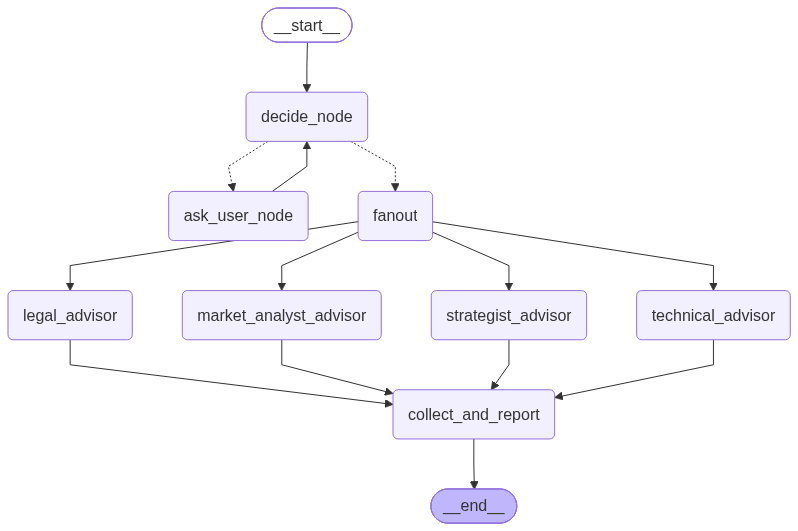

In [30]:
# Render the compiled graph structure inline.
graph

In [31]:
# Run the evaluator interactively: enter the idea, then answer follow-up
# questions until the four advisor reports and the final report are produced.
print("What is your business idea? Please provide a brief description.")
idea = input("You: ")

initial_state: State = {
    "idea": idea,
    "messages": [HumanMessage(content=idea)],
    "advisor_reports": {},
    "final_report": "" }

graph.invoke(initial_state, config={"configurable": {"thread_id": "run-1"}})

What is your business idea? Please provide a brief description.
Assistant asked: What age group of students are you targeting for your home school?


### Final Evaluation Report
# Evaluation Report for Home School with Home-like Ambiance

## Introduction
This report evaluates the feasibility and potential of establishing a home school with a home-like ambiance for children aged 4-12. The evaluation encompasses legal considerations, market potential, business strategy, and technical feasibility, providing a comprehensive overview for the founder.

## 1. Legal and Regulatory Considerations
Starting a home school involves navigating various legal and regulatory frameworks. Key considerations include:

### 1.1 Licensing and Regulatory Compliance
- **Educational Licensing**: Depending on the jurisdiction, a license may be required to operate a home school, with specific regulations on curriculum standards and teacher qualifications.
- **Zoning Laws**: Verify local zoning laws to ensure that operating a home school in a residential area is permissible.
- **Health and Safety Regulations**: Compliance with health and safety standards is essential, especially if meals or care are provided.

### 1.2 Curriculum and Educational Standards
- **Curriculum Approval**: Ensure the curriculum meets local educational standards and is approved by relevant authorities.
- **Assessment and Reporting**: Be aware of requirements for student assessments and progress reporting.

### 1.3 Liability and Insurance
- **Liability Insurance**: Obtain liability insurance to protect against potential claims related to accidents or injuries.
- **Waivers and Consent Forms**: Implement waivers for parents to acknowledge risks involved in home schooling.

### 1.4 Intellectual Property Considerations
- **Curriculum Materials**: Consider copyrighting original curriculum materials and ensuring proper licensing for third-party resources.
- **Branding and Trademarks**: Register a trademark to protect the brand identity.

### 1.5 Employment and Staffing
- **Hiring Staff**: Ensure compliance with employment laws, including background checks and qualifications.
- **Volunteer Policies**: Establish clear policies for volunteers.

### 1.6 Privacy and Data Protection
- **Student Records**: Comply with data protection regulations regarding student information.
- **Parental Consent**: Obtain consent for data collection and sharing.

### 1.7 Community Engagement and Support
- **Building Relationships**: Engage with local educational authorities and community organizations to build support.

## 2. Market Potential Evaluation
The market for a home school with a home-like ambiance is promising, driven by increasing interest in homeschooling.

### 2.1 Market Sizing
- **Target Age Group**: 4-12 years old.
- **Market Size**: Approximately 1.85 million students in the U.S. fall within this age range, with the homeschooling market projected to grow at a CAGR of 7-10% through 2025.

### 2.2 Competition Analysis
- **Direct Competitors**: Other homeschooling programs, online platforms, and traditional private schools.
- **Indirect Competitors**: Daycare centers and educational apps.

### 2.3 Target Demographics
- **Primary Customers**: Parents seeking personalized education for their children.
- **Secondary Customers**: Working parents and those dissatisfied with traditional schooling.

### 2.4 Timing and Trends
- **Current Trends**: Increased interest in homeschooling due to the pandemic and a shift towards personalized education.
- **Macroeconomic Influences**: Economic uncertainty may lead families to seek more affordable education options.

### 2.5 Market Factors
- **Regulatory Environment**: Varies by state and impacts market entry.
- **Cultural Factors**: Acceptance of homeschooling is growing, but varies by region.
- **Technological Factors**: Integration of technology is essential for enhancing the educational experience.

## 3. Business Strategy Evaluation
The business strategy focuses on positioning the home school effectively in the market.

### 3.1 Market Positioning
- **Target Market**: Parents seeking personalized education and alternatives to conventional schooling.
- **Value Proposition**: A nurturing environment that promotes emotional and social development alongside academic learning.

### 3.2 Competitive Advantages
- **Unique Learning Environment**: Differentiates from traditional institutions.
- **Personalized Education**: Customizable learning experiences.
- **Community Building**: Fosters strong relationships among families.

### 3.3 Growth Opportunities
- **Expansion of Services**: Offering extracurricular activities and online resources.
- **Partnerships**: Collaborating with local organizations and educational technology companies.
- **Franchising or Licensing**: Potential for rapid growth and brand recognition.

### 3.4 Relevant Strategic Factors
- **Regulatory Considerations**: Compliance with local education regulations is crucial.
- **Marketing Strategy**: Strong online presence and community engagement are essential.
- **Feedback Mechanisms**: Regular feedback from parents and students to refine the educational approach.

## 4. Technical Feasibility Assessment
The technical feasibility of establishing the home school involves addressing several challenges.

### 4.1 Potential Technical Challenges
- **Curriculum Development**: Requires collaboration with educational experts and adherence to standards.
- **Infrastructure Requirements**: The physical space must be conducive to learning and compliant with safety regulations.
- **Staffing**: Hiring qualified educators and providing continuous training.
- **Technology Infrastructure**: Reliable internet and a Learning Management System (LMS) are necessary.

### 4.2 Scalability Considerations
- **Expansion**: Standardizing curriculum and operational procedures for multiple locations.
- **Technology Scaling**: Utilizing cloud solutions and developing remote learning capabilities.

### 4.3 Additional Technical Factors
- **Data Privacy and Security**: Implementing measures to safeguard student information.
- **Parent Communication**: Establishing effective communication channels and feedback systems.
- **Community Engagement**: Building partnerships with local organizations.

## Conclusion
The concept of a home school with a home-like ambiance for children aged 4-12 presents a unique opportunity in the education sector. By addressing legal, market, strategic, and technical considerations, the founder can position the business for success. Careful planning and execution will be essential to navigate the complexities of this venture and capitalize on the growing demand for personalized education.

{'idea': 'My idea is to build home school with home like ambience',
 'messages': [HumanMessage(content='My idea is to build home school with home like ambience', additional_kwargs={}, response_metadata={}, id='892ecc1b-ec4d-49ab-a962-ac5858bbd490'),
  AIMessage(content='What age group of students are you targeting for your home school?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 13, 'prompt_tokens': 66, 'total_tokens': 79, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_c5012d6921', 'id': 'chatcmpl-EfWvljxqYO2VidXTveuRB7efQYKoB', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}